# Experiment No. 08 – AI-Based Customer Persona Generation from Marketing Data

**Course:** Digital Marketing (DIM) · KJSSE/IT/LYBTech/Sem-VII/DIM/2026-27
**Product studied:** ClimaSense AI – a climate-tech website for heatwave monitoring, prediction and early warning (this repository).

**Aim:** generate data-driven customer personas by segmenting the ClimaSense AI audience with K-Means clustering.

> **Data note:** no real customer data exists for this academic project (the website is frontend-only and its numbers are demo values). The dataset in `data/customers.csv` is therefore **synthetic**, generated reproducibly by `scripts/generate_dataset.py` (`np.random.default_rng(42)`). It imitates website visitors / newsletter subscribers across the five dashboard cities and deliberately contains duplicates, missing values and inconsistent spellings so the cleaning step has real work to do.

## Step 1 – Install Python and the required libraries (with `uv`)

Everything is managed by [`uv`](https://docs.astral.sh/uv/) inside this folder's own `.venv`:

```bash
uv sync                    # installs pandas, numpy, scikit-learn, matplotlib, jupyter ... from pyproject.toml
uv run python scripts/generate_dataset.py
uv run jupyter lab
```

The cell below imports the libraries and prints their versions to confirm the installation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Fixed seed so every run gives the same clusters; paths are relative to this notebook's folder.
RANDOM_STATE = 42
DATA_PATH = Path("../data/customers.csv")
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# One colour per cluster (colour-blind friendly) reused in every plot.
CLUSTER_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9", "#999999"]
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def save_and_show(fig, file_name):
    """Save the figure as a PNG snapshot for the lab manual, then display it inline."""
    fig.savefig(FIGURE_DIR / file_name, dpi=150, bbox_inches="tight")
    plt.show()


print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1


## Step 2 – Load the marketing dataset with pandas

In [2]:
raw_df = pd.read_csv(DATA_PATH)
raw_df.head()

,customer_id,age,gender,occupation,education,annual_income,city,state,country,spending_score,purchase_frequency,website_visits_per_month,avg_order_value,preferred_channel,interests,lifestyle
0,CS0680,50.0,Female,Business Owner,Graduate,1396000.0,Bengaluru,Karnataka,India,60.0,9.0,14.0,2410.0,Instagram,Cooling Products,Family first
1,CS0472,40.0,Female,Driver,High School,427000.0,Delhi,Delhi,India,21.0,3.0,13.0,650.0,Push Notification,Hydration Tips,Budget conscious
2,CS0457,27.0,MALE,Delivery Partner,High School,285000.0,mumbai,Maharashtra,India,42.0,6.0,9.0,460.0,WhatsApp,Work Hour Advisories,Budget conscious
3,CS0644,26.0,Male,Software Engineer,Graduate,544000.0,Pune,Maharashtra,India,76.0,3.0,30.0,840.0,Reddit,AI Forecasting,Sustainability minded
4,CS0747,27.0,Male,Software Engineer,Postgraduate,469000.0,Mumbai,Maharashtra,India,91.0,3.0,22.0,1040.0,Reddit,Climate Data,Sustainability minded


## Step 3 – Explore the dataset and identify relevant attributes

The columns cover the four data types from the theory:

| Data type | Columns |
|---|---|
| Demographic | `age`, `gender`, `occupation`, `education`, `annual_income` (₹) |
| Geographic | `city`, `state`, `country` |
| Behavioral | `spending_score` (1–100), `purchase_frequency` (orders/year), `website_visits_per_month`, `avg_order_value` (₹), `preferred_channel` |
| Psychographic | `interests`, `lifestyle` |

Here "purchases" mean things a ClimaSense AI visitor could buy or subscribe to: premium alert plans, cooling / heat-safety kits and organisation licences.

In [3]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 818 entries, 0 to 817
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               818 non-null    str    
 1   age                       798 non-null    float64
 2   gender                    818 non-null    str    
 3   occupation                818 non-null    str    
 4   education                 818 non-null    str    
 5   annual_income             798 non-null    float64
 6   city                      818 non-null    str    
 7   state                     818 non-null    str    
 8   country                   818 non-null    str    
 9   spending_score            798 non-null    float64
 10  purchase_frequency        818 non-null    float64
 11  website_visits_per_month  818 non-null    float64
 12  avg_order_value           796 non-null    float64
 13  preferred_channel         808 non-null    str    
 14  interests            

In [4]:
raw_df.describe()

,age,annual_income,spending_score,purchase_frequency,website_visits_per_month,avg_order_value
count,798.000000,7.980000e+02,798.000000,818.000000,818.000000,796.000000
mean,37.483709,9.137632e+05,50.005013,5.612469,14.777506,2093.592965
std,10.843549,7.243891e+05,19.849875,4.122089,7.435525,1809.447021
min,18.000000,1.000000e+05,4.000000,0.000000,3.000000,190.000000
25%,28.000000,3.265000e+05,33.000000,3.000000,9.000000,700.000000
50%,38.000000,6.435000e+05,48.000000,4.000000,13.000000,1155.000000
75%,46.000000,1.171000e+06,67.750000,8.000000,18.000000,2850.000000
max,64.000000,3.322000e+06,98.000000,19.000000,38.000000,7590.000000


In [5]:
# Data-quality counts BEFORE cleaning (kept so we can compare with the counts after cleaning).
missing_before = raw_df.isna().sum()
duplicates_before = raw_df.duplicated().sum()
print("Rows before cleaning:", len(raw_df))
print("Duplicate rows      :", duplicates_before)
print("\nMissing values per column:")
print(missing_before[missing_before > 0])

Rows before cleaning: 818
Duplicate rows      : 18

Missing values per column:
age                  20
annual_income        20
spending_score       20
avg_order_value      22
preferred_channel    10
dtype: int64


In [6]:
# Inconsistent categorical spellings are visible in the raw value counts.
for column in ["gender", "city", "preferred_channel"]:
    print(raw_df[column].value_counts(dropna=False).to_string(), "\n")

gender
Male      353
Female    319
Other      26
male       23
female     23
MALE       21
M          20
FEMALE     17
F          16 

city
Delhi         174
Mumbai        171
Pune          155
Bengaluru     137
Ahmedabad     129
Bombay         13
delhi           9
New Delhi       9
Bangalore       8
bengaluru       7
mumbai          6 

preferred_channel
Instagram            135
Email                121
WhatsApp              81
Push Notification     77
SMS                   76
Facebook              71
Webinar               63
Reddit                62
YouTube               59
LinkedIn              55
NaN                   10
whatsapp               8 



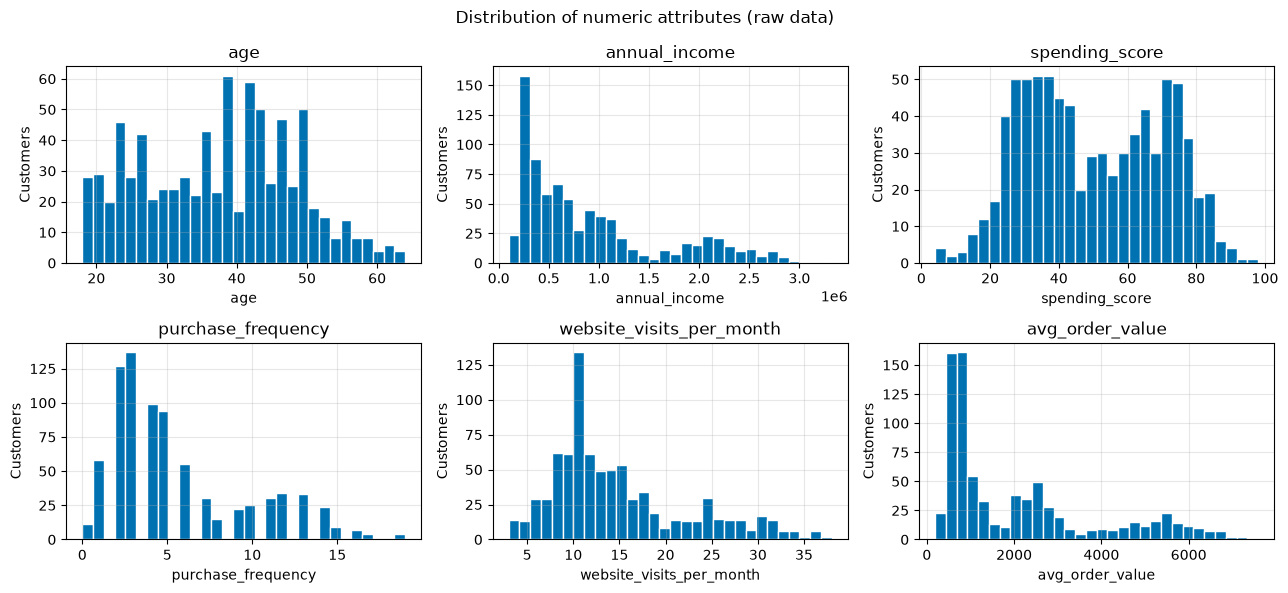

In [7]:
# Distributions of the main numeric attributes to see the audience shape before cleaning.
numeric_columns = ["age", "annual_income", "spending_score", "purchase_frequency", "website_visits_per_month", "avg_order_value"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for axis, column in zip(axes.ravel(), numeric_columns):
    axis.hist(raw_df[column].dropna(), bins=30, color=CLUSTER_COLORS[0], edgecolor="white")
    axis.set_title(column)
    axis.set_xlabel(column)
    axis.set_ylabel("Customers")
fig.suptitle("Distribution of numeric attributes (raw data)")
fig.tight_layout()
save_and_show(fig, "00_eda_distributions.png")

## Step 4 – Clean the data

1. **Remove duplicates** – exact repeated rows (the same visitor submitted twice) would double-count one person.
2. **Fix inconsistent values** – `male`, `M`, `MALE` → `Male`; `Bangalore` → `Bengaluru`; `whatsapp` → `WhatsApp`, stray spaces removed.
3. **Handle missing values** – numeric gaps are filled with the **median** (robust to outliers); the few missing channels with the **mode**.

In [8]:
clean_df = raw_df.drop_duplicates().copy()

# Map every spelling variant to one canonical label (keys are lower-case and stripped).
gender_map = {"male": "Male", "m": "Male", "female": "Female", "f": "Female", "other": "Other"}
city_map = {"bangalore": "Bengaluru", "bombay": "Mumbai", "new delhi": "Delhi"}
channel_lookup = {channel.lower(): channel for channel in raw_df["preferred_channel"].dropna().unique() if channel != "whatsapp"}

clean_df["gender"] = clean_df["gender"].str.strip().str.lower().map(gender_map)
city_key = clean_df["city"].str.strip().str.lower()
clean_df["city"] = city_key.map(city_map).fillna(city_key.str.title())
clean_df["preferred_channel"] = clean_df["preferred_channel"].str.lower().map(channel_lookup)

# Median for numeric gaps, mode for the categorical gap.
for column in ["age", "annual_income", "spending_score", "avg_order_value"]:
    clean_df[column] = clean_df[column].fillna(clean_df[column].median())
clean_df["preferred_channel"] = clean_df["preferred_channel"].fillna(clean_df["preferred_channel"].mode()[0])
clean_df = clean_df.reset_index(drop=True)

In [9]:
# Before / after comparison.
summary = pd.DataFrame({
    "before": [len(raw_df), raw_df.duplicated().sum(), raw_df.isna().sum().sum(),
               raw_df["gender"].nunique(), raw_df["city"].nunique(), raw_df["preferred_channel"].nunique()],
    "after": [len(clean_df), clean_df.duplicated().sum(), clean_df.isna().sum().sum(),
              clean_df["gender"].nunique(), clean_df["city"].nunique(), clean_df["preferred_channel"].nunique()],
}, index=["rows", "duplicate rows", "missing values", "unique gender labels", "unique city labels", "unique channel labels"])
summary

,before,after
rows,818,800
duplicate rows,18,0
missing values,92,0
unique gender labels,9,3
unique city labels,11,5
unique channel labels,11,10


In [10]:
print("Gender  :", clean_df["gender"].value_counts().to_dict())
print("City    :", clean_df["city"].value_counts().to_dict())
print("Channel :", clean_df["preferred_channel"].value_counts().to_dict())

Gender  : {'Male': 408, 'Female': 368, 'Other': 24}
City    : {'Delhi': 188, 'Mumbai': 183, 'Pune': 154, 'Bengaluru': 150, 'Ahmedabad': 125}
Channel : {'Instagram': 143, 'Email': 118, 'WhatsApp': 85, 'Push Notification': 77, 'SMS': 74, 'Facebook': 69, 'Reddit': 62, 'Webinar': 60, 'YouTube': 59, 'LinkedIn': 53}


## Step 5 – Select the features for segmentation

Segmentation uses **numeric behavioral and demographic** attributes that describe *who the customer is and how they act*: age, annual income, spending score, purchase frequency, website visits per month and average order value. ID, gender, city and the other text columns are not used to form clusters (K-Means needs numbers, and we do not want to segment by gender or location); they are used afterwards to **describe** each cluster.

In [11]:
feature_columns = ["age", "annual_income", "spending_score", "purchase_frequency",
                   "website_visits_per_month", "avg_order_value"]
features = clean_df[feature_columns]
features.head()

,age,annual_income,spending_score,purchase_frequency,website_visits_per_month,avg_order_value
0,50.0,1396000.0,60.0,9.0,14.0,2410.0
1,40.0,427000.0,21.0,3.0,13.0,650.0
2,27.0,285000.0,42.0,6.0,9.0,460.0
3,26.0,544000.0,76.0,3.0,30.0,840.0
4,27.0,469000.0,91.0,3.0,22.0,1040.0


## Step 6 – Normalise the features with `StandardScaler`

Income is in lakhs of rupees while purchase frequency is a single-digit number. K-Means uses Euclidean distance, so without scaling income would dominate every distance. `StandardScaler` rescales each feature to mean 0 and standard deviation 1.

In [12]:
scaler = StandardScaler()
scaled_features = pd.DataFrame(scaler.fit_transform(features), columns=feature_columns)

print("BEFORE scaling")
display(features.describe().loc[["mean", "std", "min", "max"]].round(2))
print("AFTER scaling")
display(scaled_features.describe().loc[["mean", "std", "min", "max"]].round(2))

BEFORE scaling


,age,annual_income,spending_score,purchase_frequency,website_visits_per_month,avg_order_value
mean,37.36,899042.50,50.07,5.62,14.86,2055.19
std,10.71,711371.01,19.57,4.13,7.48,1788.19
min,18.00,100000.00,4.00,0.00,3.00,190.00
max,64.00,3322000.00,98.00,19.00,38.00,7590.00


AFTER scaling


,age,annual_income,spending_score,purchase_frequency,website_visits_per_month,avg_order_value
mean,-0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.81,-1.12,-2.36,-1.36,-1.59,-1.04
max,2.49,3.41,2.45,3.24,3.10,3.10


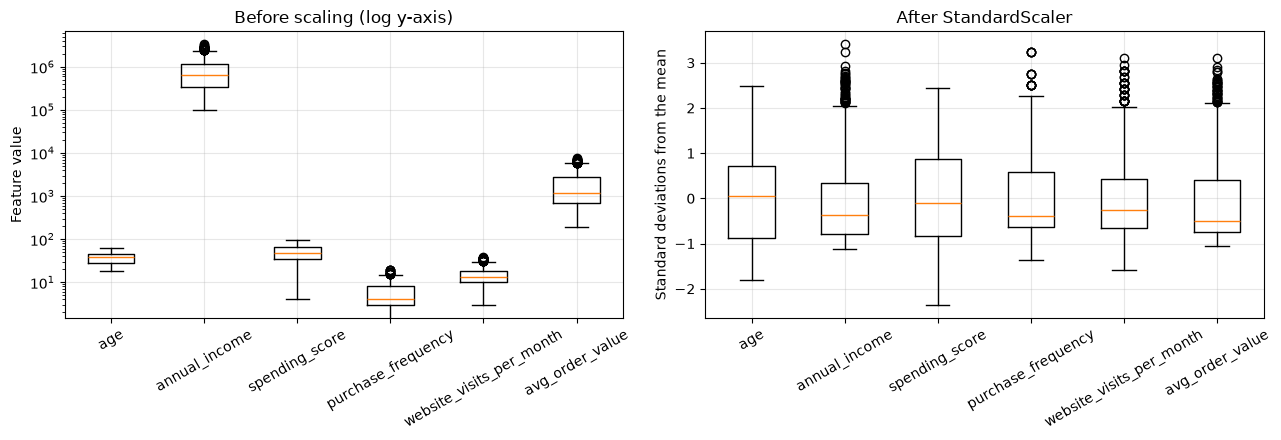

In [13]:
# Side-by-side view of the spread of each feature before and after scaling.
fig, (axis_raw, axis_scaled) = plt.subplots(1, 2, figsize=(13, 4.5))
axis_raw.boxplot([features[column] for column in feature_columns], tick_labels=feature_columns)
axis_raw.set_yscale("log")
axis_raw.set_title("Before scaling (log y-axis)")
axis_raw.set_ylabel("Feature value")
axis_scaled.boxplot([scaled_features[column] for column in feature_columns], tick_labels=feature_columns)
axis_scaled.set_title("After StandardScaler")
axis_scaled.set_ylabel("Standard deviations from the mean")
for axis in (axis_raw, axis_scaled):
    axis.tick_params(axis="x", rotation=30)
fig.tight_layout()
save_and_show(fig, "01_scaling_before_after.png")

## Step 7 – Apply K-Means to group customers into segments

K-Means works like this: choose *k* → place *k* random centroids → assign every customer to the nearest centroid → recompute each centroid as the mean of its members → repeat until the assignments stop changing.

**Choosing k.** We try k = 2 … 10 and use two checks:
* **Elbow method** – inertia (within-cluster sum of squares) always falls as k grows; the "elbow" is where extra clusters stop paying off.
* **Silhouette score** – how well each customer fits its own cluster versus the next nearest (closer to 1 is better).

In [14]:
k_values = range(2, 11)
inertias, silhouettes = [], []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(scaled_features)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(scaled_features, model.labels_))

k_results = pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette": silhouettes})
k_results.round(3)

,k,inertia,silhouette
0,2,2882.098,0.451
1,3,1803.186,0.456
2,4,930.549,0.554
3,5,859.963,0.448
4,6,811.651,0.361
5,7,751.554,0.295
6,8,711.260,0.215
7,9,671.312,0.215
8,10,645.034,0.216


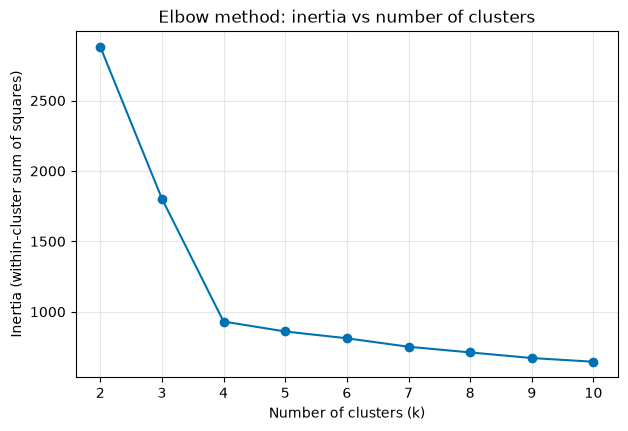

In [15]:
fig, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(k_results["k"], k_results["inertia"], marker="o", color=CLUSTER_COLORS[0])
axis.set_title("Elbow method: inertia vs number of clusters")
axis.set_xlabel("Number of clusters (k)")
axis.set_ylabel("Inertia (within-cluster sum of squares)")
save_and_show(fig, "02_elbow.png")

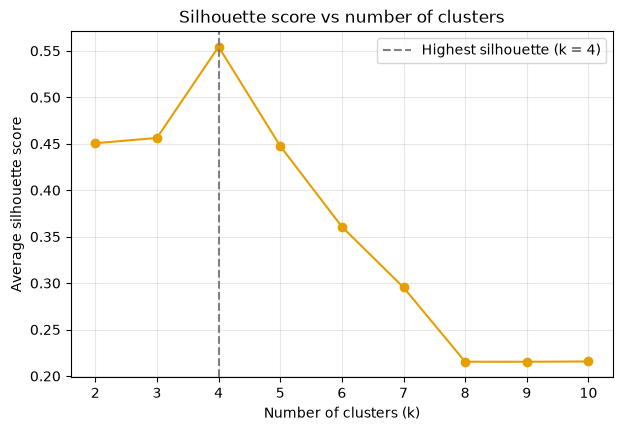

k with the highest silhouette score: 4


In [16]:
best_k = int(k_results.loc[k_results["silhouette"].idxmax(), "k"])
fig, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(k_results["k"], k_results["silhouette"], marker="o", color=CLUSTER_COLORS[1])
axis.axvline(best_k, linestyle="--", color="grey", label=f"Highest silhouette (k = {best_k})")
axis.set_title("Silhouette score vs number of clusters")
axis.set_xlabel("Number of clusters (k)")
axis.set_ylabel("Average silhouette score")
axis.legend()
save_and_show(fig, "03_silhouette.png")
print("k with the highest silhouette score:", best_k)

### Justification of k

The elbow plot bends sharply at **k = 4**: inertia drops steeply from k = 2 to k = 4 and only slowly after that. The silhouette curve peaks at the same value, so both tests agree. Four segments is also a practical number for a small marketing team to run separate campaigns for. We therefore fit K-Means with **k = 4** (`random_state=42`, `n_init=10` for reproducible results).

In [17]:
K = 4
assert K == best_k, "The chosen k should match the silhouette peak; re-check the plots."

kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(scaled_features)
clean_df["cluster"] = kmeans.labels_
print("Silhouette score for k = 4:", round(silhouette_score(scaled_features, kmeans.labels_), 3))
clean_df["cluster"].value_counts().sort_index()

Silhouette score for k = 4: 0.554


cluster
0    198
1    159
2    200
3    243
Name: count, dtype: int64

## Step 8 – Visualise the clusters

Three views: (a) a scatter plot of two key features with centroids, (b) a PCA 2-D projection of all six scaled features, (c) bar charts of the standardised feature means per cluster.

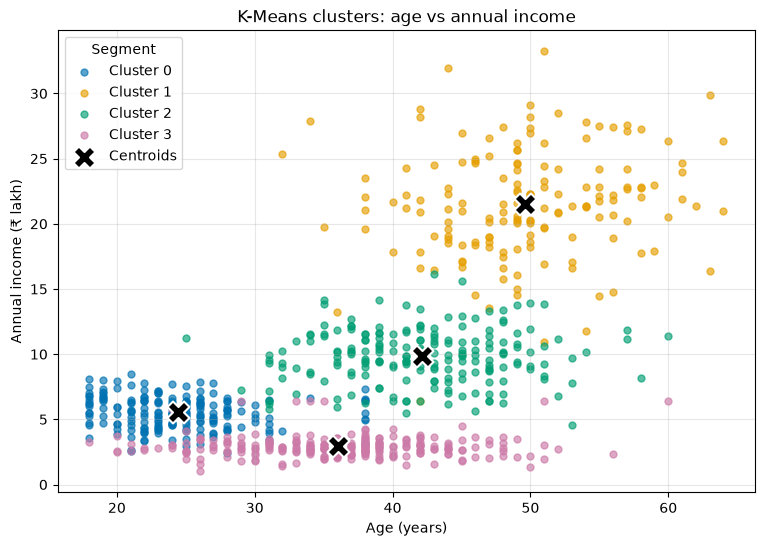

In [18]:
# Centroids live in scaled space, so convert them back to real units for plotting.
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=feature_columns)

fig, axis = plt.subplots(figsize=(9, 6))
for cluster_id in range(K):
    members = clean_df[clean_df["cluster"] == cluster_id]
    axis.scatter(members["age"], members["annual_income"] / 100_000, s=25, alpha=0.65,
                 color=CLUSTER_COLORS[cluster_id], label=f"Cluster {cluster_id}")
axis.scatter(centroids["age"], centroids["annual_income"] / 100_000, marker="X", s=250,
             color="black", edgecolor="white", linewidth=1.5, label="Centroids", zorder=5)
axis.set_title("K-Means clusters: age vs annual income")
axis.set_xlabel("Age (years)")
axis.set_ylabel("Annual income (₹ lakh)")
axis.legend(title="Segment")
save_and_show(fig, "04_clusters_scatter.png")

/home/user/dim_project/digital-marketing/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


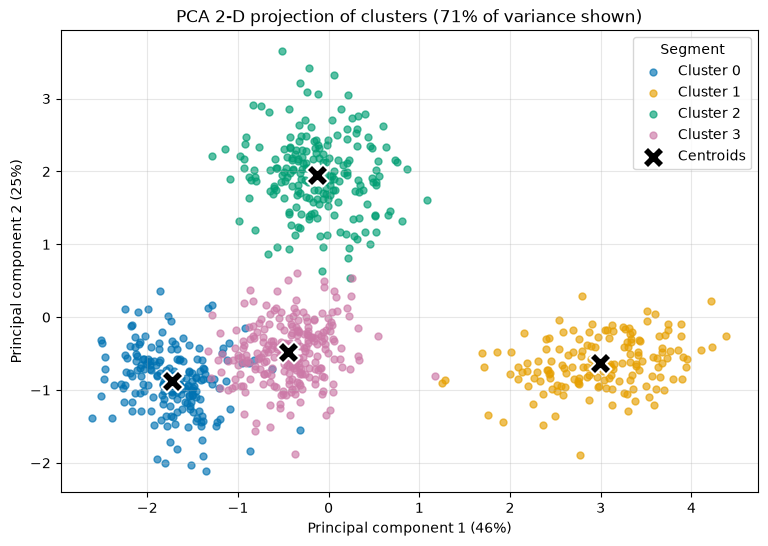

In [19]:
# PCA squeezes the six scaled features into two axes so all clusters can be seen at once.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
projected = pca.fit_transform(scaled_features)
projected_centroids = pca.transform(kmeans.cluster_centers_)

fig, axis = plt.subplots(figsize=(9, 6))
for cluster_id in range(K):
    mask = clean_df["cluster"] == cluster_id
    axis.scatter(projected[mask, 0], projected[mask, 1], s=25, alpha=0.65,
                 color=CLUSTER_COLORS[cluster_id], label=f"Cluster {cluster_id}")
axis.scatter(projected_centroids[:, 0], projected_centroids[:, 1], marker="X", s=250,
             color="black", edgecolor="white", linewidth=1.5, label="Centroids", zorder=5)
axis.set_title(f"PCA 2-D projection of clusters ({pca.explained_variance_ratio_.sum():.0%} of variance shown)")
axis.set_xlabel(f"Principal component 1 ({pca.explained_variance_ratio_[0]:.0%})")
axis.set_ylabel(f"Principal component 2 ({pca.explained_variance_ratio_[1]:.0%})")
axis.legend(title="Segment")
save_and_show(fig, "05_clusters_pca.png")

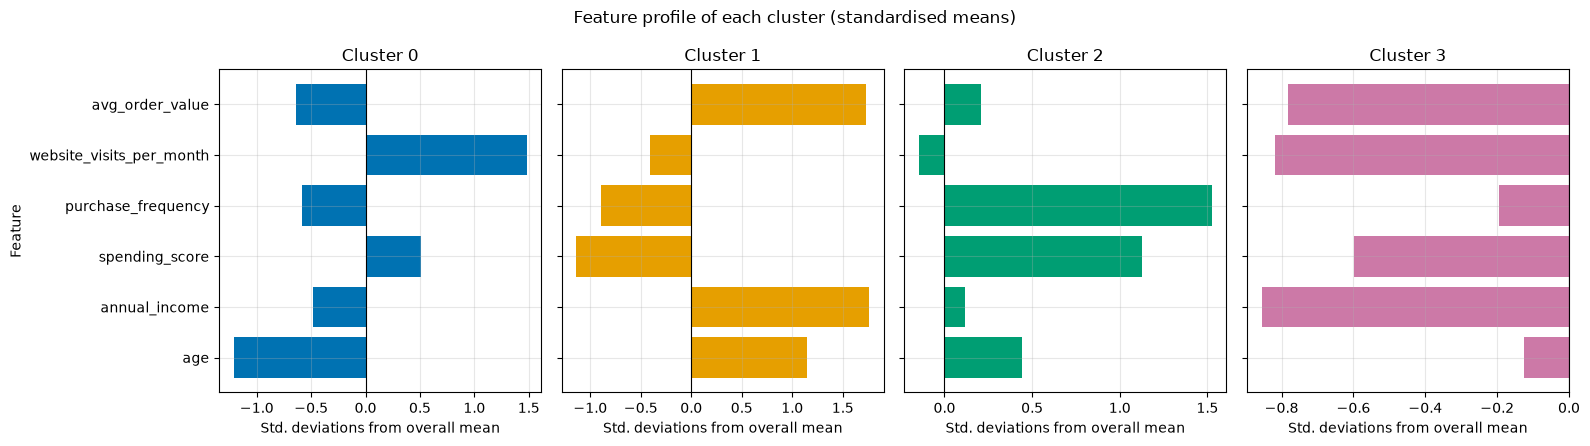

In [20]:
# Standardised means show which features make each cluster stand out (above / below average).
scaled_means = scaled_features.groupby(clean_df["cluster"]).mean()

fig, axes = plt.subplots(1, K, figsize=(16, 4.5), sharey=True)
for cluster_id, axis in enumerate(axes):
    axis.barh(feature_columns, scaled_means.loc[cluster_id], color=CLUSTER_COLORS[cluster_id])
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set_title(f"Cluster {cluster_id}")
    axis.set_xlabel("Std. deviations from overall mean")
axes[0].set_ylabel("Feature")
fig.suptitle("Feature profile of each cluster (standardised means)")
fig.tight_layout()
save_and_show(fig, "06_cluster_feature_means.png")

## Step 9 – Analyse each cluster and create customer personas

First a **cluster profile table**: numeric means plus the most common (mode) channel, interest, lifestyle, occupation and city, and the cluster's size. Every persona field below is derived from this table, not invented.

In [21]:
def top_values(series, count=2):
    """Most common categories, joined for display."""
    return ", ".join(series.value_counts().head(count).index)


profile = clean_df.groupby("cluster").agg(
    customers=("customer_id", "count"),
    avg_age=("age", "mean"),
    avg_income=("annual_income", "mean"),
    avg_spending_score=("spending_score", "mean"),
    avg_purchase_frequency=("purchase_frequency", "mean"),
    avg_visits_per_month=("website_visits_per_month", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    top_channels=("preferred_channel", top_values),
    top_interests=("interests", top_values),
    top_lifestyle=("lifestyle", lambda s: top_values(s, 1)),
    top_occupations=("occupation", top_values),
    top_city=("city", lambda s: top_values(s, 1)),
)
profile.insert(1, "pct_of_customers", (profile["customers"] / len(clean_df) * 100).round(1))
profile = profile.round({"avg_age": 1, "avg_income": 0, "avg_spending_score": 1,
                         "avg_purchase_frequency": 1, "avg_visits_per_month": 1, "avg_order_value": 0})
profile.to_csv(OUTPUT_DIR / "cluster_profile.csv")
profile

,customers,pct_of_customers,avg_age,avg_income,avg_spending_score,avg_purchase_frequency,avg_visits_per_month,avg_order_value,top_channels,top_interests,top_lifestyle,top_occupations,top_city
cluster,,,,,,,,,,,,,
0,198,24.8,24.4,552611.0,60.1,3.2,25.9,918.0,"Instagram, Reddit","Climate Data, AI Forecasting",Digital native,"Software Engineer, Researcher",Pune
1,159,19.9,49.6,2152085.0,27.8,1.9,11.8,5144.0,"Webinar, LinkedIn","Early Warning Systems, Urban Heat Policy",Community focused,"Urban Planner, Municipal Officer",Delhi
2,200,25.0,42.1,983582.0,72.1,11.9,13.8,2424.0,"Email, Facebook","Health Advisories, Child and Elder Care",Family first,"Teacher, Doctor",Bengaluru
3,243,30.4,36.0,291848.0,38.4,4.8,8.7,657.0,"WhatsApp, Push Notification","Heat Safety Alerts, Work Hour Advisories",Budget conscious,"Delivery Partner, Driver",Delhi


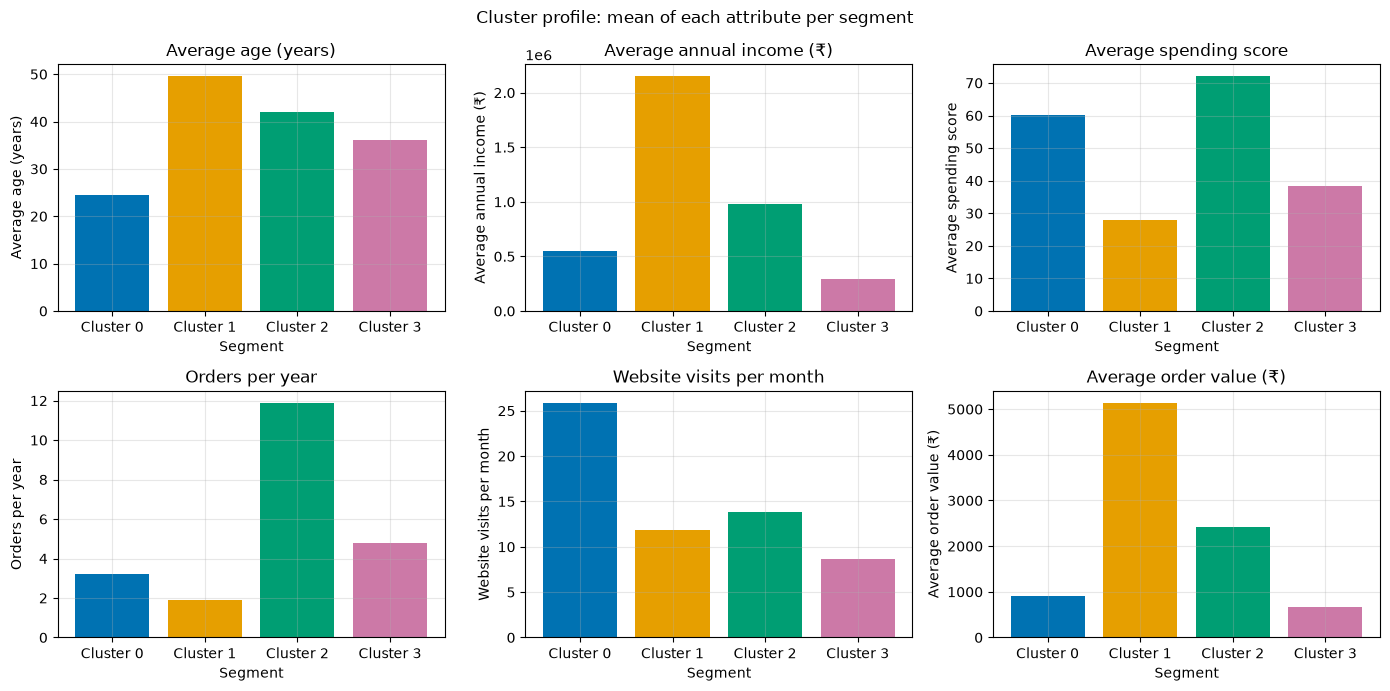

In [22]:
# Bar charts of the raw cluster means (real units) for the snapshot in the report.
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
profile_plots = [("avg_age", "Average age (years)"), ("avg_income", "Average annual income (₹)"),
                 ("avg_spending_score", "Average spending score"), ("avg_purchase_frequency", "Orders per year"),
                 ("avg_visits_per_month", "Website visits per month"), ("avg_order_value", "Average order value (₹)")]
for axis, (column, label) in zip(axes.ravel(), profile_plots):
    axis.bar([f"Cluster {c}" for c in profile.index], profile[column], color=CLUSTER_COLORS[:K])
    axis.set_title(label)
    axis.set_xlabel("Segment")
    axis.set_ylabel(label)
fig.suptitle("Cluster profile: mean of each attribute per segment")
fig.tight_layout()
save_and_show(fig, "07_cluster_profile_bars.png")

### Naming the personas

Each cluster is matched to a persona using its numbers, and the persona fields (age group, income level, spending behavior) are computed from the profile table by simple rules. The rules are: the **youngest** cluster is the tech-savvy enthusiast group, the **highest-income** cluster is the civic / institutional buyer, the **lowest-income** cluster is the outdoor-worker group, and the remaining cluster is the health-conscious family group. Shopping preferences, goals, pain points and strategies are marketing interpretations of those numbers and are tied to what ClimaSense AI actually offers (dashboard, prediction simulator, awareness articles, newsletter).

In [23]:
# Match clusters to personas from the numbers (see the markdown above for the rules).
persona_by_cluster = {
    profile["avg_age"].idxmin(): "Young Climate-Tech Enthusiast",
    profile["avg_income"].idxmax(): "Civic Heat-Policy Planner",
    profile["avg_income"].idxmin(): "Outdoor Heat-Exposed Worker",
}
persona_by_cluster[next(c for c in profile.index if c not in persona_by_cluster)] = "Health-Conscious Family Planner"
assert len(set(persona_by_cluster.values())) == K, "Each cluster needs its own persona."

# Marketing interpretation of each persona: what they buy, want, struggle with, and how to reach them.
persona_playbook = {
    "Outdoor Heat-Exposed Worker": dict(
        shopping_preferences="Low-cost, small purchases: basic heat-safety kits, hydration packs and free or cheap alerts; price sensitive.",
        goals="Stay safe during peak-heat work hours and avoid losing income to heat illness.",
        pain_points="Little time on the site, low budget, needs simple language and local-language alerts, cannot check a dashboard while working.",
        marketing_strategy="Push notifications and WhatsApp/SMS heat alerts sent before peak hours; short vernacular awareness videos; free-tier alerts first, then low-priced safety kits via retargeting ads; SEO for 'heatwave safety for outdoor workers'.",
    ),
    "Health-Conscious Family Planner": dict(
        shopping_preferences="Frequent, high-value purchases: cooling products, premium family alert plans; values trust and quality.",
        goals="Protect children and elderly relatives and plan the family's day around heat risk.",
        pain_points="Unsure which advice to trust, worried about heatstroke in vulnerable family members, short on time to research.",
        marketing_strategy="Email newsletter with weekly heat-risk digest and care checklists; Facebook and Instagram content marketing on child and elder safety; retargeting of simulator users with premium family-plan offers; loyalty and referral rewards.",
    ),
    "Young Climate-Tech Enthusiast": dict(
        shopping_preferences="Low purchase frequency but heavy exploration: mid-priced add-ons, data access and API-style features; buys after trying the product.",
        goals="Understand how AI predicts heatwaves, play with data, and share climate insights with peers.",
        pain_points="Wants transparency about the model and data sources, dislikes generic or alarmist content, ignores traditional ads.",
        marketing_strategy="Interactive prediction-simulator campaigns; short-form video and reels on Instagram and YouTube; Reddit and community posts explaining the model; social sharing buttons and referral hooks; SEO around 'AI heatwave prediction'; content marketing with data stories.",
    ),
    "Civic Heat-Policy Planner": dict(
        shopping_preferences="Rare but very high-ticket purchases: organisation licences, regional dashboards and reports; long evaluation cycle.",
        goals="Build early-warning and heat-action plans for a city, ward or organisation.",
        pain_points="Needs credible, citable data, integration with existing systems, and proof of impact before spending public money.",
        marketing_strategy="LinkedIn thought-leadership and paid ads targeting municipal and NGO roles; webinars and whitepapers on early-warning systems; email nurture sequence ending in a demo request; SEO for 'heatwave early warning system for cities'; case-study content.",
    ),
}


def describe_age(mean_age):
    if mean_age < 30:
        return f"Young adults (18-30), average age {mean_age:.0f}"
    if mean_age < 45:
        return f"Adults (30-45), average age {mean_age:.0f}"
    return f"Mature adults (45+), average age {mean_age:.0f}"


def describe_income(mean_income):
    level = "Low" if mean_income < 500_000 else "Middle to upper-middle" if mean_income < 1_500_000 else "High"
    return f"{level} income, about ₹{mean_income / 100_000:.1f} lakh per year"


def describe_spending(row):
    tier = "High" if row.avg_spending_score >= 65 else "Moderate" if row.avg_spending_score >= 45 else "Low"
    rhythm = "frequent" if row.avg_purchase_frequency >= 10 else "occasional" if row.avg_purchase_frequency >= 4 else "rare"
    ticket = "high-ticket" if row.avg_order_value >= 2_000 else "small-ticket"
    return (f"{tier} spending score ({row.avg_spending_score:.0f}/100); {rhythm}, {ticket} purchases: "
            f"{row.avg_purchase_frequency:.0f} orders/year at about ₹{row.avg_order_value:,.0f} each")


rows = []
for cluster_id, row in profile.iterrows():
    persona_name = persona_by_cluster[cluster_id]
    playbook = persona_playbook[persona_name]
    rows.append({
        "cluster": cluster_id,
        "persona_name": persona_name,
        "customers": row.customers,
        "pct_of_customers": row.pct_of_customers,
        "age_group": describe_age(row.avg_age),
        "income_level": describe_income(row.avg_income),
        "spending_behavior": describe_spending(row),
        "shopping_preferences": playbook["shopping_preferences"],
        "interests": f"{row.top_interests}; lifestyle: {row.top_lifestyle}",
        "goals": playbook["goals"],
        "pain_points": playbook["pain_points"],
        "preferred_channels": row.top_channels,
        "recommended_marketing_strategy": playbook["marketing_strategy"],
    })
personas = pd.DataFrame(rows).sort_values("cluster").reset_index(drop=True)

In [24]:
# Print each persona as a readable card.
for _, persona in personas.iterrows():
    print("=" * 100)
    print(f"Cluster {persona['cluster']}: {persona['persona_name']}  ({persona['customers']} customers, {persona['pct_of_customers']}%)")
    print("=" * 100)
    for field in ["age_group", "income_level", "spending_behavior", "shopping_preferences", "interests",
                  "goals", "pain_points", "preferred_channels", "recommended_marketing_strategy"]:
        print(f"{field.replace('_', ' ').title():<34}: {persona[field]}")
    print()

Cluster 0: Young Climate-Tech Enthusiast  (198 customers, 24.8%)
Age Group                         : Young adults (18-30), average age 24
Income Level                      : Middle to upper-middle income, about ₹5.5 lakh per year
Spending Behavior                 : Moderate spending score (60/100); rare, small-ticket purchases: 3 orders/year at about ₹918 each
Shopping Preferences              : Low purchase frequency but heavy exploration: mid-priced add-ons, data access and API-style features; buys after trying the product.
Interests                         : Climate Data, AI Forecasting; lifestyle: Digital native
Goals                             : Understand how AI predicts heatwaves, play with data, and share climate insights with peers.
Pain Points                       : Wants transparency about the model and data sources, dislikes generic or alarmist content, ignores traditional ads.
Preferred Channels                : Instagram, Reddit
Recommended Marketing Strategy    : Inter

## Step 10 – Summarise the personas and suggest digital marketing strategies

The table below is saved to `outputs/personas.csv`. The chart shows how large each segment is so the marketing team can decide where to spend effort first.

In [25]:
personas.to_csv(OUTPUT_DIR / "personas.csv", index=False)
personas[["cluster", "persona_name", "customers", "pct_of_customers", "preferred_channels", "recommended_marketing_strategy"]]

,cluster,persona_name,customers,pct_of_customers,preferred_channels,recommended_marketing_strategy
0,0,Young Climate-Tech Enthusiast,198,24.8,"Instagram, Reddit",Interactive prediction-simulator campaigns; sh...
1,1,Civic Heat-Policy Planner,159,19.9,"Webinar, LinkedIn",LinkedIn thought-leadership and paid ads targe...
2,2,Health-Conscious Family Planner,200,25.0,"Email, Facebook",Email newsletter with weekly heat-risk digest ...
3,3,Outdoor Heat-Exposed Worker,243,30.4,"WhatsApp, Push Notification",Push notifications and WhatsApp/SMS heat alert...


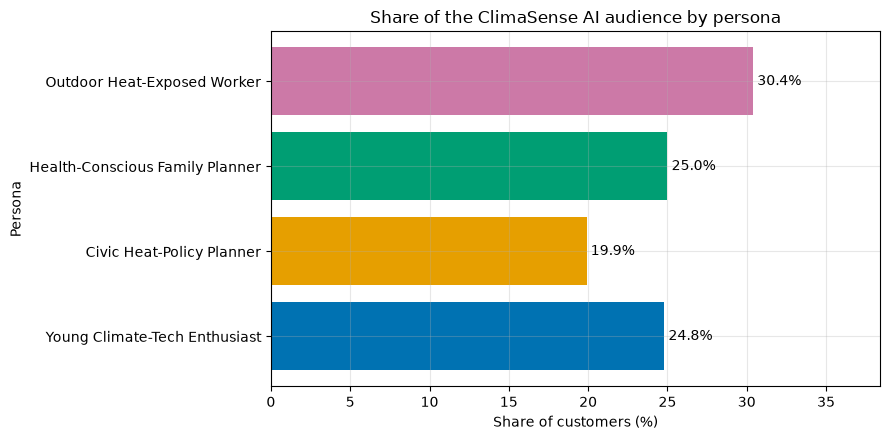

In [26]:
fig, axis = plt.subplots(figsize=(9, 4.5))
bars = axis.barh(personas["persona_name"], personas["pct_of_customers"], color=CLUSTER_COLORS[:K])
axis.bar_label(bars, fmt="%.1f%%", padding=3)
axis.set_xlim(0, personas["pct_of_customers"].max() + 8)
axis.set_title("Share of the ClimaSense AI audience by persona")
axis.set_xlabel("Share of customers (%)")
axis.set_ylabel("Persona")
fig.tight_layout()
save_and_show(fig, "08_persona_sizes.png")

### Summary

K-Means (k = 4, chosen by the elbow and silhouette tests on `StandardScaler`-normalised data) split the cleaned ClimaSense AI audience into four personas. Each persona differs clearly in age, income, spending and preferred channels, so each needs its own message and channel mix: alerts and messaging apps for outdoor workers, email and social content for families, interactive social and video content for young enthusiasts, and LinkedIn plus webinars for civic planners. The full text is in `outputs/personas.csv` and `outputs/report.md`.